# 6. Apprentissage semi-supervisé : `Charpy conforme`

**Question** : les soudures **sans** résultat Charpy exploitable (on connaît leur composition et leur procédé, mais pas leur conformité) permettent-elles de mieux prédire la conformité Charpy que le modèle supervisé retenu par l'équipe ?

Le sujet demande d'appliquer **au moins une méthode semi-supervisée en justifiant son choix et sa pertinence**. On applique les **trois familles du cours** et on compare chaque méthode au **modèle supervisé retenu par l'équipe** dans le notebook 3, avec exactement le même protocole.

**Cible** : `Charpy conforme` telle que définie dans le notebook 2 (section 3.1) : la soudure atteint **47 J à −40 °C** (seuil EN ISO 2560-A). Règle : conforme si $E \ge 47$ J à $T \le -40$ °C, non conforme si $E < 47$ J à $T \ge -40$ °C, et, pour les soudures ayant à la fois T(28 J) et T(100 J), conformité déduite de T(47 J) obtenue par interpolation linéaire. Les autres lignes sont **non étiquetées** : ce sont les données $U$ du semi-supervisé.

**Ce qui est repris du notebook 3 (pour que la comparaison soit juste)**
- le **même découpage train / test** (relu dans `05_reporting/.../split_train_test.csv`) : le test n'est utilisé qu'une seule fois, à la fin ;
- la **même imputation métier** (`WeldImputer`) et la même variable construite (`CE_IIW`) ;
- le **modèle supervisé retenu par l'équipe** (relu dans `modele_retenu.json`), qui sert de modèle de base au self-training et de référence ;
- la même validation croisée groupée par publication (`StratifiedGroupKFold`, 5 plis, `random_state=42`).

Toutes les fonctions sont dans `utils_semi_supervise.py`, réutilisé par le notebook 7 (profil de résistance).

## Rappel : les trois familles de méthodes 

On dispose de $m$ exemples étiquetés $S = \{(x_i, y_i)\}_{i=1}^{m}$ et de $u$ exemples non étiquetés $U = \{x_i\}_{i=m+1}^{m+u}$. On cherche une fonction $h : x \mapsto y$ meilleure que celle apprise sur $S$ seul, en exploitant la structure de $U$.

| Famille | Principe | Hypothèse du cours | Méthodes testées |
|---|---|---|---|
| **Discriminante** (self-training) | Un modèle supervisé prédit $U$ ; les prédictions les plus **sûres** deviennent des pseudo-étiquettes ; on ré-entraîne et on itère (« version discriminante de CEM ») | Séparation en zone de faible densité | Self-training classique · Self-training équilibré par classe |
| **Graphe** (label spreading) | Graphe des $k$ plus proches voisins sur $S \cup U$ ; les étiquettes diffusent vers les voisins : $\tilde Y^* = (S + \lambda(D - W))^{-1} S Y$ | Lissité / variété | Label spreading |
| **Générative** (CEM semi-supervisé) | Une loi gaussienne par classe ; étape E (probabilités des non-étiquetées), C (affectation), M (ré-estimation sur $S \cup U$) | Lissité / clusters | CEM semi-supervisé |

**Référence** : toutes les méthodes sont comparées au modèle retenu par l'équipe (notebook 3), entraîné sur les mêmes soudures étiquetées. La question posée est donc pratique : *une méthode semi-supervisée fait-elle mieux que notre meilleur modèle supervisé ?*

**Ces méthodes ne fonctionnent que si leurs hypothèses sont vérifiées** (Singh, Nowak & Zhu, 2008 ; Oliver et al., 2018) : on les teste en section 2 avant d'appliquer les méthodes.

## 0. Imports et paramètres

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import utils_semi_supervise as ssl

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")

RANDOM_STATE = 42                 # même graine que les notebooks 3 et 5
N_FOLDS = 5                       # même nombre de plis
FRACTIONS = [0.1, 0.25, 0.5, 1.0] # part des étiquettes d'entraînement conservées (courbe d'apprentissage)
N_TIRAGES = 3                     # tirages par fraction < 100 % (lisse le bruit de la courbe)
N_BOOT = 500                      # rééchantillonnages bootstrap
METRIQUE = "Accuracy_ponderee"    # métrique principale (justification en section 3)

CIBLE = "Charpy conforme"
METHODE_REF = "A_sans_selection"  # le semi-supervisé utilise toutes les variables, comme la méthode A

P_DONNEES = Path("..") / "1. Données"
P_REF = P_DONNEES / "05_reporting" / "prediction_Charpy conforme" / "Charpy_conforme"
P_SORTIE = P_DONNEES / "05_reporting" / "semi_supervise" / "charpy"
P_FIG = Path("..") / "3. Résultats" / "figures"
P_FIG.mkdir(parents=True, exist_ok=True)

def savefig(nom):
    plt.savefig(P_FIG / f"ssl_charpy_{nom}.png", dpi=150, bbox_inches="tight")

## 1. Données

- Entrées : les mêmes que le notebook 3. Toutes les cibles sont retirées (une cible ne doit pas servir à en prédire une autre), ainsi que `Charpy temperature` et `Charpy impact toughness`, déjà supprimées dans le notebook 2 car elles **construisent** l'étiquette.
- **Non-étiquetées $U$** : les lignes où `Charpy conforme` est vide. Celles qui viennent d'une **publication du test** sont retirées : même sans étiquette, leurs entrées décrivent les soudures du test, et le graphe ou le self-training pourraient s'en servir pour « préparer » le test.

In [2]:
df = pd.read_csv(P_DONNEES / "02_intermediate" / "welddb_processed_vf.csv", sep=";")
corresp = pd.read_csv(P_DONNEES / "02_intermediate" / "correspondance_between_names_units_vf.csv", sep=";")
TARGETS = corresp.loc[corresp["Role"] == "Quality indicator", "Feature"].tolist()

COLONNES_A_RETIRER = TARGETS + ["Charpy temperature", "Charpy impact toughness"]
jeux = ssl.preparer_jeux(df, masque_etiquete=df[CIBLE].notna(),
                         chemin_split=P_REF / "split_train_test.csv", col_cible="cible",
                         colonnes_a_retirer=COLONNES_A_RETIRER)

y_tr = jeux["y_lab"].iloc[jeux["train_idx"]]
y_te = jeux["y_lab"].iloc[jeux["test_idx"]]
print(f"Entrées : {jeux['X_lab'].shape[1]} variables")
print(f"Étiquetées : {len(jeux['y_lab'])}  (train {len(y_tr)}, test {len(y_te)}) — split relu du notebook 3")
print(f"  train : {y_tr.value_counts().to_dict()}   test : {y_te.value_counts().to_dict()}   (1 = conforme)")
print(f"Non étiquetées utilisables : {len(jeux['X_unl'])}  ({jeux['n_unl_exclues_test']} exclues car issues d'une publication du test)")
print(f"Publications : {jeux['g_lab'].nunique()} étiquetées, "
      f"{jeux['g_lab'][jeux['y_lab'] == 0].nunique()} contiennent des non conformes")

Entrées : 25 variables
Étiquetées : 569  (train 461, test 108) — split relu du notebook 3
  train : {1: 373, 0: 88}   test : {1: 91, 0: 17}   (1 = conforme)
Non étiquetées utilisables : 935  (134 exclues car issues d'une publication du test)
Publications : 35 étiquetées, 12 contiennent des non conformes


In [3]:
# Modèle supervisé retenu par l'équipe (notebook 3, méthode A) : référence et modèle de base du self-training
ref = ssl.charger_reference(P_REF / METHODE_REF / "modele_retenu.json")
NOM_REF = ref["modele_retenu"]
modele_ref = ssl.modele_depuis_json(NOM_REF, ref["hyperparametres_retenu"])
print(f"Modèle retenu par l'équipe : {NOM_REF}  {ref['hyperparametres_retenu']}")
print(f"Score de test publié (notebook 3) : " + ", ".join(f"{k} = {v:.3f}" for k, v in ref["score_test"].items()))

Modèle retenu par l'équipe : XGBoost (défaut)  {}
Score de test publié (notebook 3) : Accuracy = 0.944, Accuracy_ponderee = 0.824, F1 = 0.968, Precision = 0.938, Recall = 1.000, ROC_AUC = 0.804, LogLoss = 0.498


## 2. Les hypothèses du semi-supervisé sont-elles vérifiées ?

Le semi-supervisé n'apporte quelque chose que si les non-étiquetées **renseignent sur la forme du problème** (cours CM8). Quatre vérifications, toutes faites sur le **train** uniquement (le test n'est pas regardé, sauf en 2.4 où l'on n'utilise que ses entrées, jamais ses étiquettes) :

| Vérification | Hypothèse testée | Ce qu'on attend si l'hypothèse tient |
|---|---|---|
| 2.1 Publications communes | $U$ et $S$ viennent de la même « population » | une grande part de $U$ vient de publications qui ont aussi des étiquetées |
| 2.2 Superposition (ACP) | $U$ est dans la même zone de l'espace que $S$ | les nuages se recouvrent |
| 2.3 Lissité | deux soudures proches ont la même classe | accord avec les voisins nettement supérieur au hasard, **y compris avec des voisins d'autres publications** |
| 2.4 Ponts | $U$ « comble les trous » entre train et test | les soudures du test sont plus proches d'une non-étiquetée que d'une étiquetée |

In [4]:
X_tr = jeux["X_lab"].iloc[jeux["train_idx"]]
prep_h = ssl.PretraitementSSL().fit(pd.concat([X_tr, jeux["X_unl"]], ignore_index=True))
Z_tr, Z_unl = prep_h.transform(X_tr), prep_h.transform(jeux["X_unl"])
Z_te = prep_h.transform(jeux["X_lab"].iloc[jeux["test_idx"]])     # entrées du test seulement (2.4)
g_tr = jeux["g_lab"].iloc[jeux["train_idx"]]

hyp = {}
hyp["part de U issue de publications étiquetées"] = ssl.part_sources_communes(g_tr, jeux["g_unl"])
print(f"2.1  {hyp['part de U issue de publications étiquetées']:.0%} des non-étiquetées viennent d'une publication qui a aussi des soudures étiquetées (train)")

2.1  53% des non-étiquetées viennent d'une publication qui a aussi des soudures étiquetées (train)


In [5]:
fig, ax = plt.subplots(figsize=(8, 6))
ssl.figure_superposition_acp(Z_tr, Z_unl, y_tr, "2.2  ACP des entrées : étiquetées (train) et non étiquetées",
                             noms_classes=("non conforme", "conforme"), ax=ax)
plt.tight_layout(); savefig("acp_superposition"); plt.show()

<Figure size 800x600 with 1 Axes>

In [6]:
lissite = ssl.test_lissite(Z_tr, y_tr, g_tr, k=5)
ponts = ssl.test_ponts(Z_tr, Z_unl, Z_te)
hyp.update(lissite.to_dict()); hyp.update(ponts.to_dict())
print("2.3  Lissité"); print(lissite.round(3).to_string())
print("\n2.4  Ponts"); print(ponts.round(3).to_string())
hypotheses = pd.Series(hyp)

2.3  Lissité
accord attendu par hasard                                       0.691
accord avec les 5 plus proches voisins                          0.964
accord avec les 5 plus proches voisins d'AUTRES publications    0.848

2.4  Ponts
distance médiane test -> étiquetée la plus proche                     1.127
distance médiane test -> soudure la plus proche (étiquetée ou non)    1.084
part du test dont la plus proche voisine est NON étiquetée            0.389


### 2.5 Bilan : hypothèses partiellement vérifiées



- **2.1 Publications communes : 53 % seulement.** Près de la moitié des soudures non étiquetées viennent d'études **sans aucun résultat Charpy exploitable**. Dans ces zones, aucune méthode ne peut propager d'information fiable : seule une partie de $U$ peut réellement aider.
- **2.2 Superposition : partielle.** Les étiquetées sont concentrées dans une zone dense (en bas à gauche : métaux fondus C-Mn faiblement alliés), alors que beaucoup de non-étiquetées occupent des zones **sans étiquette** (haut du graphique, droite : aciers plus alliés). Les non conformes ne forment **pas un seul groupe** mais plusieurs petits paquets (en haut à gauche, à droite) : l'hypothèse de *clusters* (« un cluster = une classe ») n'est que partiellement vraie.
- **2.3 Lissité : vérifiée.** 96 % d'accord avec les 5 plus proches voisins, contre 69 % attendus par hasard, et encore **85 % avec des voisins d'autres publications**. Deux soudures proches dans l'espace des entrées ont donc bien, le plus souvent, la même conformité, et ce n'est pas seulement un effet « même étude ». C'est l'hypothèse qui justifie les méthodes à graphe et génératives.
- **2.4 Ponts : faibles.** Pour 39 % des soudures du test, la plus proche voisine est une non-étiquetée, mais la distance médiane ne baisse que de 1,13 à 1,08 : $U$ ne rapproche presque pas le test des données d'entraînement.

**Conséquence attendue** : l'hypothèse de lissité tient, donc le semi-supervisé est **pertinent en principe** ; mais comme $U$ couvre en grande partie d'autres familles d'aciers et comble peu l'écart avec le test, le **gain attendu est modeste**.

## 3. Protocole d'évaluation

**Principe** : on évalue **toujours sur de vraies étiquettes**, et chaque méthode semi-supervisée est comparée au **modèle retenu par l'équipe**, entraîné sur les mêmes soudures étiquetées.

| Étape | Choix | Justification |
|---|---|---|
| Découpage | Validation croisée **sur le train du notebook 3**, `StratifiedGroupKFold` (5 plis, graine 42) ; le test n'est utilisé qu'en section 6 | mêmes conditions que le supervisé ; une publication est entièrement d'un côté (sinon le modèle reconnaît la « signature » d'une étude) |
| Non-étiquetées | $U$ = non-étiquetées hors publications du pli de validation (et du test) | cas réaliste d'une soudure issue d'une étude jamais vue |
| Prétraitement | `WeldImputer` + `CE_IIW` + standardisation + one-hot, appris sur $S \cup U$ pour **toutes** les méthodes | imputation de l'équipe ; la standardisation est indispensable aux méthodes à base de distances (graphe, gaussiennes) et sans effet sur les arbres ; l'apprendre sur $S \cup U$ pour tout le monde isole l'effet de l'**algorithme** |
| Courbe d'apprentissage | on garde 10 %, 25 %, 50 %, 100 % des étiquettes de $S$ ; les autres sont **cachées** et rejoignent $U$ ; **3 tirages** par fraction | le semi-supervisé est censé aider surtout quand les étiquettes sont rares ; plusieurs tirages lissent le bruit (chaque pli ne garde que quelques non conformes à 10 %) |
| Métriques | calculées sur les **prédictions hors-pli regroupées** des 5 plis (*pooled*) | un pli peut contenir très peu de non conformes : un score par pli n'aurait pas de sens (Forman & Scholz, 2010) |
| Incertitude | **bootstrap sur les publications** ; gain semi-supervisé − supervisé par **bootstrap apparié** | les soudures d'une même publication ne sont pas indépendantes ; l'appariement (mêmes publications tirées pour les deux méthodes) annule le bruit commun |

**Métrique principale : l'accuracy pondérée (*balanced accuracy*)**, moyenne des rappels des deux classes (0,5 = hasard). Le notebook 3 sélectionne avec le F1 de la classe 1, mais ici la classe 1 (« conforme ») est **majoritaire (≈ 81 %)** : un modèle qui répond toujours « conforme » aurait un F1 ≈ 0,90 tout en ne détectant aucune soudure fragile. On affiche aussi le **F1 de la classe 0** (« non conforme », la classe qui compte pour un industriel : une soudure fragile non détectée est l'erreur dangereuse) et l'AUC.

**Règle de choix, fixée avant de voir les résultats** :
1. le modèle semi-supervisé **retenu** est celui qui a la meilleure accuracy pondérée en **validation croisée imbriquée** (hyperparamètres réglés automatiquement, section 5.3) avec 100 % des étiquettes ;
2. on ne le déclare **utile** que si la borne basse de l'IC à 95 % de son gain apparié sur le modèle de l'équipe est **positive**.

## 4. Méthodes

Le code est dans `utils_semi_supervise.py` (section 4).

**Self-training classique** (`SelfTrainingClassifier`, seuil 0,9) : le modèle retenu par l'équipe prédit $U$, les prédictions de probabilité ≥ 0,9 deviennent des pseudo-étiquettes, on ré-entraîne, jusqu'à 10 fois.

**Self-training équilibré** (`SelfTrainingEquilibre`, codé pour ce projet) : avec la première définition de la cible (44 non conformes), le self-training classique n'ajoutait que des pseudo-étiquettes « conforme », les plus sûres, et renforçait son propre biais (*biais de confirmation*). Ici, à chaque itération, on ajoute **pour chaque classe** les soudures les plus sûrement prédites dans cette classe (probabilité ≥ 0,7), **en respectant la proportion des classes** des vraies étiquettes (10 % de $U$ par itération).

**Label spreading** (`SafeLabelSpreading`) : graphe des 10 plus proches voisins, $\alpha = 0{,}2$. Une soudure sans aucun voisin informé a une probabilité 0/0 : on lui attribue la proportion des classes au lieu de la classe 0 par défaut (qui fausserait les scores).

**CEM semi-supervisé** (`SemiSupervisedCEM`, algorithme du cours) : une gaussienne par classe, dans l'espace des **10 premières composantes de l'ACP** (hypothèse de variété : estimer une covariance en ~40 dimensions avec une centaine de non conformes serait instable), covariances diagonales.

**Hyperparamètres** : en section 5, valeurs usuelles fixées à l'avance (ci-dessus), pour comparer les méthodes « telles quelles » et tracer la courbe d'apprentissage ; en section 5.3, ils sont **réglés par validation croisée imbriquée**, et ce sont ces versions réglées qui servent au choix du modèle et au test final.

In [7]:
methodes, paires = ssl.methodes_classification(modele_ref, NOM_REF, n_voisins=10, n_composantes=10)
NOM_REF_LONG = paires[0][1]
pd.DataFrame([(f, s_) for f, _, s_ in paires], columns=["famille", "méthode semi-supervisée"]).assign(**{"comparée à": NOM_REF_LONG})

,famille,méthode semi-supervisée,comparée à
0,Discriminante (self-training),Self-training classique,"XGBoost (défaut) (supervisé, retenu par l'équipe)"
1,Discriminante (self-training),Self-training équilibré,"XGBoost (défaut) (supervisé, retenu par l'équipe)"
2,Graphe,Label spreading,"XGBoost (défaut) (supervisé, retenu par l'équipe)"
3,Générative,CEM semi-supervisé,"XGBoost (défaut) (supervisé, retenu par l'équipe)"


## 5. Résultats en validation croisée

In [8]:
preds_cv = ssl.evaluer_ssl_cv(jeux, methodes, fractions=FRACTIONS, n_tirages=N_TIRAGES,
                              n_folds=N_FOLDS, random_state=RANDOM_STATE)
scores = ssl.scores_regroupes(preds_cv)

pli 1/5 terminé


pli 2/5 terminé


pli 3/5 terminé


pli 4/5 terminé


pli 5/5 terminé


In [9]:
# Synthèse avec 100 % des étiquettes
METRIQUES_AFF = ["Accuracy_ponderee", "F1_classe_0", "F1", "F1_macro", "Recall", "ROC_AUC"]
s100 = scores.xs(1.0, level="fraction")[METRIQUES_AFF].copy()
ic = {m: ssl.ic_bootstrap(preds_cv[(preds_cv["methode"] == m) & (preds_cv["fraction"] == 1.0)], METRIQUE, N_BOOT)
      for m in s100.index}
s100[f"{METRIQUE} IC95"] = [f"[{ic[m][0]:.2f} ; {ic[m][1]:.2f}]" for m in s100.index]
print("Validation croisée, 100 % des étiquettes (prédictions hors-pli regroupées ; IC95 bootstrap sur les publications)")
s100.round(3)

Validation croisée, 100 % des étiquettes (prédictions hors-pli regroupées ; IC95 bootstrap sur les publications)


,Accuracy_ponderee,F1_classe_0,F1,F1_macro,Recall,ROC_AUC,Accuracy_ponderee IC95
methode,,,,,,,
"XGBoost (défaut) (supervisé, retenu par l'équipe)",0.727,0.591,0.921,0.756,0.954,0.934,[0.61 ; 0.84]
Self-training classique,0.814,0.714,0.936,0.825,0.946,0.903,[0.59 ; 0.95]
Self-training équilibré,0.654,0.452,0.897,0.674,0.933,0.864,[0.49 ; 0.88]
Label spreading,0.641,0.435,0.912,0.674,0.976,0.795,[0.49 ; 0.77]
CEM semi-supervisé,0.840,0.667,0.894,0.780,0.839,0.904,[0.64 ; 0.96]


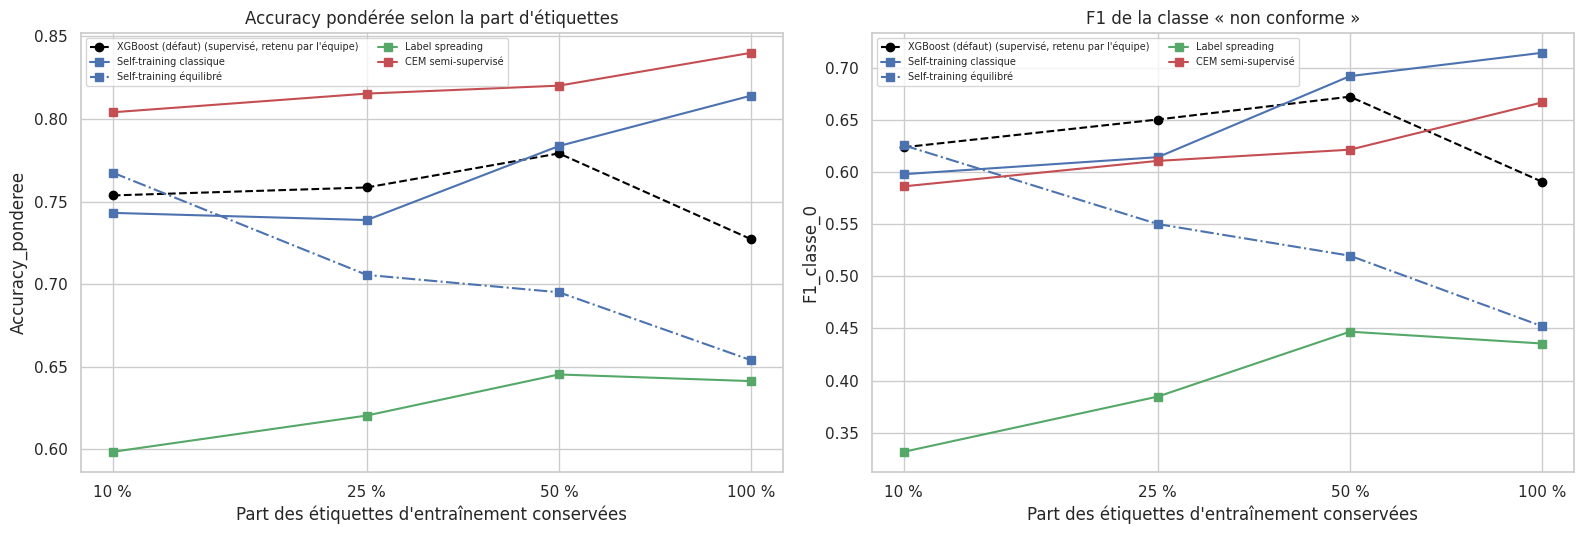

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
ssl.courbe_apprentissage(scores, paires, METRIQUE, "Accuracy pondérée selon la part d'étiquettes", ax=axes[0])
ssl.courbe_apprentissage(scores, paires, "F1_classe_0", "F1 de la classe « non conforme »", ax=axes[1])
plt.tight_layout(); savefig("courbe_apprentissage"); plt.show()

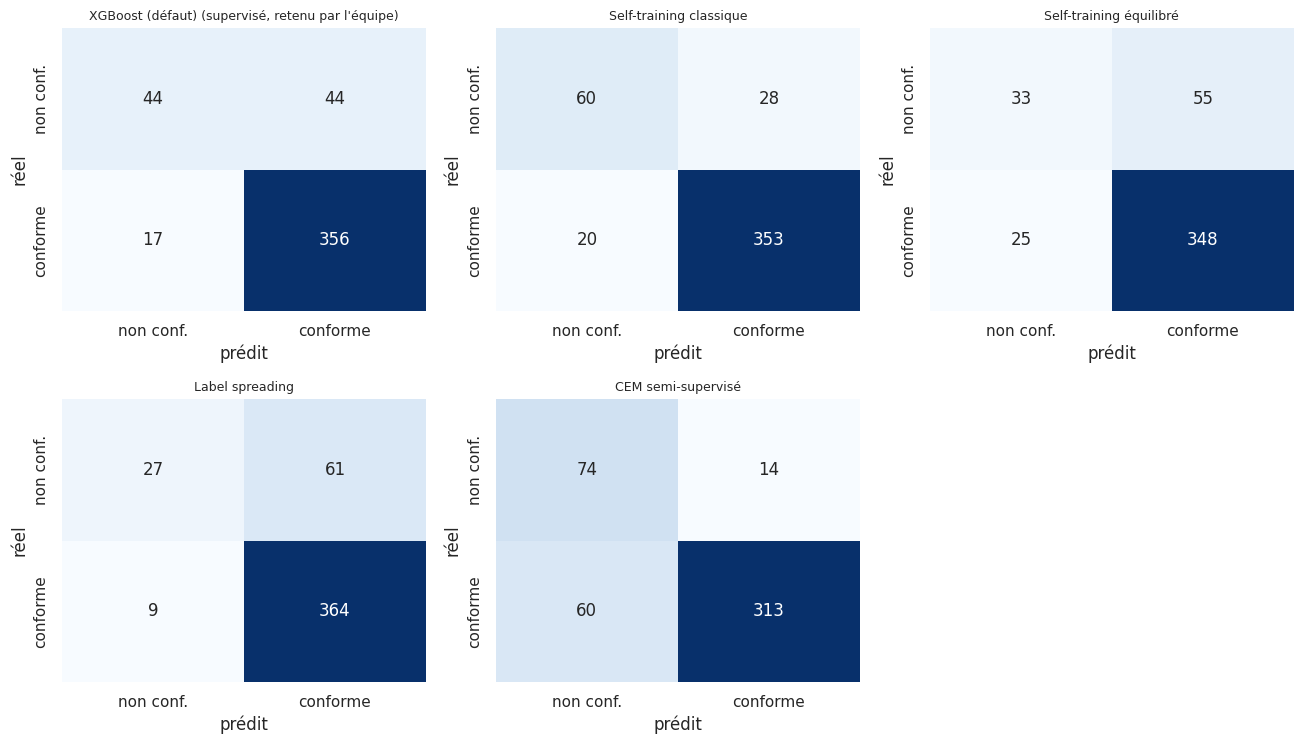

In [11]:
ssl.matrices_confusion(preds_cv, list(methodes), noms_classes=("non conf.", "conforme"))
savefig("confusion_cv"); plt.show()

In [12]:
gains = ssl.tableau_gains(preds_cv, paires, METRIQUE, FRACTIONS, n_boot=N_BOOT)
print("Gain en accuracy pondérée (semi-supervisé − modèle de l'équipe), bootstrap apparié sur les publications")
gains.pivot_table(index=["famille", "semi-supervisé"], columns="fraction", values="gain").round(3)

Gain en accuracy pondérée (semi-supervisé − modèle de l'équipe), bootstrap apparié sur les publications


fraction                                                0.10   0.25   0.50  \
famille                       semi-supervisé                                 
Discriminante (self-training) Self-training classique -0.011 -0.020  0.004   
                              Self-training équilibré  0.014 -0.053 -0.084   
Graphe                        Label spreading         -0.155 -0.138 -0.134   
Générative                    CEM semi-supervisé       0.050  0.057  0.041   

fraction                                                1.00  
famille                       semi-supervisé                  
Discriminante (self-training) Self-training classique  0.087  
                              Self-training équilibré -0.073  
Graphe                        Label spreading         -0.086  
Générative                    CEM semi-supervisé       0.113

In [13]:
gains[gains["fraction"] == 1.0].set_index("semi-supervisé")[["supervisé", "gain", "IC95_bas", "IC95_haut", "P(gain > 0)"]].round(3)

,supervisé,gain,IC95_bas,IC95_haut,P(gain > 0)
semi-supervisé,,,,,
Self-training classique,"XGBoost (défaut) (supervisé, retenu par l'équipe)",0.087,-0.121,0.223,0.806
Self-training équilibré,"XGBoost (défaut) (supervisé, retenu par l'équipe)",-0.073,-0.190,0.074,0.190
Label spreading,"XGBoost (défaut) (supervisé, retenu par l'équipe)",-0.086,-0.291,0.057,0.160
CEM semi-supervisé,"XGBoost (défaut) (supervisé, retenu par l'équipe)",0.113,-0.143,0.284,0.856


### 5.2 Analyse des résultats en validation croisée

**Rappel de lecture** : chaque méthode semi-supervisée est comparée au **modèle retenu par l'équipe** (XGBoost, courbe noire en pointillés). Un gain n'est établi que si son IC à 95 % apparié exclut 0.

| Méthode (100 % des étiquettes) | Acc. pondérée | Gain sur le XGBoost [IC95 apparié] | P(gain > 0) | Non conformes détectées / 88 |
|---|---|---|---|---|
| XGBoost de l'équipe (référence) | 0,727 | — | — | 44 (17 fausses alertes) |
| Self-training classique | **0,814** | +0,087 [−0,12 ; +0,22] | 0,81 | **60** (20 fausses alertes) |
| Self-training équilibré | 0,654 | −0,073 [−0,19 ; +0,07] | 0,19 | 33 (25) |
| Label spreading | 0,641 | −0,086 [−0,29 ; +0,06] | 0,16 | 27 (9) |
| CEM semi-supervisé | **0,840** | +0,113 [−0,14 ; +0,28] | 0,86 | **74** (60) |

**1. Aucun gain n'est statistiquement établi** : tous les intervalles contiennent 0. Avec 88 non conformes d'entraînement réparties dans une dizaine de publications, l'incertitude reste grande.

**2. Self-training classique : un gain net, mais seulement avec toutes les étiquettes.** Il détecte 16 non conformes de plus que le XGBoost de départ pour 3 fausses alertes de plus. Contrairement à la théorie, il **n'aide pas quand les étiquettes sont rares** (−0,01 à 10 %, −0,02 à 25 %) : avec peu d'étiquettes, le XGBoost de départ est peu fiable et ses pseudo-étiquettes aussi. Le self-training ne vaut que ce que vaut son modèle de départ.

**3. Self-training équilibré : moins bon que la référence dès 25 %.** Cette variante avait été conçue pour corriger le biais observé avec l'ancienne définition de la cible (44 non conformes : seules des pseudo-étiquettes « conforme » étaient ajoutées). Avec la nouvelle définition, ce biais a disparu (voir 5.1) : forcer des pseudo-étiquettes « non conforme » revient à ajouter les **moins sûres**, donc plus d'erreurs.

**4. Label spreading : en dessous du XGBoost à toutes les fractions** (de −0,09 à −0,16), avec ses hyperparamètres par défaut. Il fait très peu de fausses alertes (9) mais ne détecte que 27 non conformes : la diffusion passe surtout par les zones denses, majoritairement conformes, et les petits paquets de non conformes sont « noyés ». *Le réglage de la section 5.3 améliore nettement ce point.*

**5. CEM : le meilleur score moyen, à toutes les fractions** (+0,04 à +0,11 sur le XGBoost). Il détecte beaucoup plus de non conformes (74 sur 88), mais au prix de nombreuses fausses alertes (60) : il **déplace la frontière** vers la classe minoritaire. L'accuracy pondérée récompense ce compromis parce que les deux classes y pèsent autant ; un industriel qui veut limiter les contrôles inutiles le jugerait moins favorablement.

**6. Les conclusions dépendent de la définition de la cible.** Avec l'ancienne définition (47 J à −20 °C, 44 non conformes), le label spreading était la meilleure méthode et le self-training ne servait à rien ; avec la définition actuelle, c'est l'inverse. À signaler dans le rapport : le classement des méthodes semi-supervisées n'est **pas robuste** sur cette base.

### 5.1 Diagnostic du self-training : quelles pseudo-étiquettes sont ajoutées ?

Pour comprendre le comportement des deux self-trainings, on regarde, sur tout le train, combien de pseudo-étiquettes de chaque classe ils ajoutent, comparé à la proportion réelle des classes.

In [14]:
X_S = jeux["X_lab"].iloc[jeux["train_idx"]]
Z_S, Z_U = prep_h.transform(X_S), prep_h.transform(jeux["X_unl"])
Z_SU = np.vstack([Z_S, Z_U]); y_SU = np.concatenate([y_tr.to_numpy(), -np.ones(len(Z_U), dtype=int)])

st = ssl.clone(methodes["Self-training classique"][0]).fit(Z_SU, y_SU)
pseudo = st.transduction_[len(Z_S):][st.labeled_iter_[len(Z_S):] > 0]
ste = ssl.clone(methodes["Self-training équilibré"][0]).fit(Z_SU, y_SU)
diag = pd.DataFrame({
    "classique": pd.Series(pseudo).value_counts().reindex([0, 1], fill_value=0),
    "équilibré": pd.Series(ste.n_pseudo_par_classe_).reindex([0, 1], fill_value=0),
    "vraies étiquettes (train)": y_tr.value_counts().reindex([0, 1]),
}).rename(index={0: "non conforme", 1: "conforme"})
diag.loc["part de non conformes"] = diag.loc["non conforme"] / diag.sum()
print(f"Non-étiquetées disponibles : {len(Z_U)}")
diag.round(3)

Non-étiquetées disponibles : 935


,classique,équilibré,vraies étiquettes (train)
non conforme,151.000,174.000,88.000
conforme,746.000,733.000,373.000
part de non conformes,0.168,0.192,0.191


### 5.2 bis Lecture du diagnostic

Avec la définition actuelle, le self-training **classique** ajoute environ **17 % de pseudo-étiquettes « non conforme »**, proche de la proportion réelle (19 %) : il **n'est plus biaisé** vers la classe majoritaire, contrairement à ce qu'on observait avec l'ancienne définition (44 non conformes, presque uniquement des pseudo-étiquettes « conforme »). C'est ce qui explique qu'il fonctionne maintenant.

Le self-training **équilibré** impose 19 % de non conformes : les pseudo-étiquettes supplémentaires sont celles dont le modèle est **le moins sûr**, d'où sa dégradation. **Leçon** : le pseudo-étiquetage équilibré est un remède au biais de confirmation, utile seulement quand ce biais existe.

### 5.3 Réglage des hyperparamètres par validation croisée imbriquée

Jusqu'ici, les hyperparamètres (seuil du self-training, $k$ et $\alpha$ du graphe, nombre de composantes de l'ACP) étaient fixés à la main. Les régler améliore souvent les résultats, mais **les choisir sur les mêmes plis que ceux qui servent à évaluer** donnerait un score trop optimiste : on choisirait la configuration qui a eu de la chance sur ces plis.

**Validation croisée imbriquée** (Varma & Simon, 2006 ; Cawley & Talbot, 2010) :
- **boucle externe** : les 5 mêmes plis qu'avant, qui ne servent **qu'à évaluer** ;
- **boucle interne** : dans chaque pli externe, le train est redécoupé en 3 plis (toujours groupés par publication) ; chaque configuration de la grille y est testée, et la meilleure (accuracy pondérée) est ré-entraînée sur tout le train du pli externe, puis évaluée sur son pli de validation, **jamais vu pendant le réglage**.

Le score obtenu estime donc honnêtement la performance d'une méthode **dont les hyperparamètres sont réglés automatiquement**. Les configurations choisies peuvent varier d'un pli à l'autre : c'est normal, et leur stabilité est une information en soi.

Le XGBoost de l'équipe garde les hyperparamètres choisis dans le notebook 3 (il a déjà été réglé et sélectionné par validation croisée).

| Méthode | Hyperparamètres testés |
|---|---|
| Self-training classique | seuil de confiance ∈ {0,7 ; 0,8 ; 0,9 ; 0,95} |
| Self-training équilibré | seuil ∈ {0,6 ; 0,7 ; 0,8 ; 0,9} × part de $U$ ajoutée par itération ∈ {5 % ; 10 %} |
| Label spreading | $k$ ∈ {5, 10, 15, 25} × $\alpha$ ∈ {0,1 ; 0,2 ; 0,5 ; 0,8} |
| CEM | nombre de composantes de l'ACP ∈ {5, 10, 15} |

Les grilles sont volontairement petites : avec ~460 soudures étiquetées, un réglage plus fin sur-apprendrait les plis internes.

In [15]:
preds_n, choix_n = ssl.evaluer_ssl_cv_imbrique(jeux, methodes, n_folds=N_FOLDS, n_inner=3,
                                               metrique=METRIQUE, random_state=RANDOM_STATE)
scores_n = ssl.scores_regroupes(preds_n).xs(1.0, level="fraction")
comparaison = pd.DataFrame({
    "sans réglage (section 5)": s100[METRIQUE],
    "réglé (CV imbriquée)": scores_n[METRIQUE],
})
comparaison["effet du réglage"] = comparaison["réglé (CV imbriquée)"] - comparaison["sans réglage (section 5)"]
ic_n = {m: ssl.ic_bootstrap(preds_n[preds_n["methode"] == m], METRIQUE, N_BOOT) for m in scores_n.index}
comparaison["IC95 réglé"] = [f"[{ic_n[m][0]:.2f} ; {ic_n[m][1]:.2f}]" for m in comparaison.index]
comparaison["F1_classe_0 réglé"] = scores_n["F1_classe_0"]
print("Accuracy pondérée en validation croisée (100 % des étiquettes)")
comparaison.round(3)

pli externe 1/5 terminé


pli externe 2/5 terminé


pli externe 3/5 terminé


pli externe 4/5 terminé


pli externe 5/5 terminé


Accuracy pondérée en validation croisée (100 % des étiquettes)


,sans réglage (section 5),réglé (CV imbriquée),effet du réglage,IC95 réglé,F1_classe_0 réglé
methode,,,,,
"XGBoost (défaut) (supervisé, retenu par l'équipe)",0.727,0.727,0.000,[0.61 ; 0.84],0.591
Self-training classique,0.814,0.829,0.015,[0.62 ; 0.95],0.753
Self-training équilibré,0.654,0.649,-0.005,[0.50 ; 0.87],0.446
Label spreading,0.641,0.739,0.098,[0.50 ; 0.94],0.603
CEM semi-supervisé,0.840,0.850,0.010,[0.65 ; 0.97],0.682


In [16]:
# Configurations choisies par la boucle interne, pour chaque pli externe (stabilité du réglage)
(choix_n.assign(parametres=choix_n["parametres"].map(lambda d: ", ".join(f"{k.split('__')[-1]}={v}" for k, v in d.items()) or "(fixés)"))
        .pivot(index="methode", columns="fold", values="parametres")
        .rename(columns=lambda f: f"pli {f + 1}"))

fold,pli 1,pli 2,pli 3,pli 4,pli 5
methode,,,,,
CEM semi-supervisé,n_components=10,n_components=5,n_components=5,n_components=5,n_components=5
Label spreading,"n_neighbors=10, alpha=0.2","n_neighbors=15, alpha=0.8","n_neighbors=25, alpha=0.1","n_neighbors=25, alpha=0.1","n_neighbors=25, alpha=0.1"
Self-training classique,threshold=0.7,threshold=0.7,threshold=0.8,threshold=0.7,threshold=0.7
Self-training équilibré,"seuil=0.6, part_par_iter=0.1","seuil=0.6, part_par_iter=0.1","seuil=0.6, part_par_iter=0.05","seuil=0.7, part_par_iter=0.05","seuil=0.7, part_par_iter=0.05"
"XGBoost (défaut) (supervisé, retenu par l'équipe)",(fixés),(fixés),(fixés),(fixés),(fixés)


In [17]:
gains_n = ssl.tableau_gains(preds_n, paires, METRIQUE, [1.0], n_boot=N_BOOT)
print("Gain des méthodes RÉGLÉES sur le modèle de l'équipe (bootstrap apparié sur les publications)")
gains_n.set_index("semi-supervisé")[["supervisé", "gain", "IC95_bas", "IC95_haut", "P(gain > 0)"]].round(3)

Gain des méthodes RÉGLÉES sur le modèle de l'équipe (bootstrap apparié sur les publications)


,supervisé,gain,IC95_bas,IC95_haut,P(gain > 0)
semi-supervisé,,,,,
Self-training classique,"XGBoost (défaut) (supervisé, retenu par l'équipe)",0.102,-0.056,0.223,0.852
Self-training équilibré,"XGBoost (défaut) (supervisé, retenu par l'équipe)",-0.078,-0.181,0.056,0.176
Label spreading,"XGBoost (défaut) (supervisé, retenu par l'équipe)",0.012,-0.236,0.211,0.558
CEM semi-supervisé,"XGBoost (défaut) (supervisé, retenu par l'équipe)",0.123,-0.133,0.297,0.870


### 5.4 Analyse du réglage

| Méthode | Sans réglage → réglé | Gain sur le XGBoost de l'équipe [IC95 apparié] | P(gain > 0) |
|---|---|---|---|
| Self-training classique | 0,814 → **0,829** | **+0,10** [−0,06 ; +0,22] | 0,85 |
| Self-training équilibré | 0,654 → 0,649 | −0,08 [−0,18 ; +0,06] | 0,18 |
| Label spreading | 0,641 → **0,739** | +0,01 [−0,24 ; +0,21] | 0,56 |
| CEM semi-supervisé | 0,840 → **0,850** | **+0,12** [−0,13 ; +0,30] | 0,87 |

*(Le XGBoost de l'équipe garde ses hyperparamètres : 0,727 dans les deux cas.)*

**1. Le réglage profite surtout au label spreading (+0,10).** La boucle interne choisit le plus souvent un **grand voisinage** ($k = 25$) et un **faible $\alpha$** (0,1), c'est-à-dire une diffusion qui reste proche des vraies étiquettes. Les mauvais résultats de la section 5 venaient donc surtout de réglages par défaut mal adaptés : réglé, le label spreading rejoint le niveau du XGBoost (+0,01), sans le dépasser.

**2. Self-training classique : léger mieux (+0,015).** Le seuil de 0,7 est choisi dans 4 plis sur 5 : accepter des pseudo-étiquettes un peu moins sûres, mais plus nombreuses, aide ici. Gain sur le XGBoost : +0,10, avec un intervalle qui contient toujours 0.

**3. CEM : le meilleur score réglé (0,850) et le plus grand gain moyen (+0,12)**, mais l'intervalle reste très large ([−0,13 ; +0,30]) : selon les publications tirées, le CEM peut être bien meilleur ou nettement moins bon que le XGBoost. Le nombre de composantes choisi passe de 10 à 5 selon les plis : signe que le modèle gaussien est **instable** sur cette base.

**4. Les choix varient d'un pli à l'autre** (label spreading : de $k=10, \alpha=0{,}2$ à $k=25, \alpha=0{,}1$). Avec ~370 soudures étiquetées par pli externe et 3 plis internes, le réglage lui-même est bruité. C'est pourquoi les grilles sont petites et pourquoi l'on évalue la **procédure** de réglage (validation croisée imbriquée) plutôt qu'une configuration unique.

**Bilan** : le réglage **améliore les scores** (surtout le label spreading), mais **aucun gain sur le modèle de l'équipe ne devient statistiquement significatif**. Le CEM et le self-training classique restent en tête, sans preuve de supériorité.

## 6. Modèle retenu et évaluation finale sur le test

Application de la règle fixée en section 3 (sur les résultats **réglés** de la section 5.3), puis évaluation **une seule fois** sur le test du notebook 3. Pour le modèle final, les hyperparamètres sont réglés une dernière fois par validation croisée interne sur **tout le train** (même grille, même procédure). La **décision** porte sur deux modèles, entraînés sur le **même train** (+ $U$ pour le semi-supervisé) :
- le modèle **semi-supervisé retenu** ;
- le **modèle retenu par l'équipe** dans le notebook 3, ré-entraîné ici avec le même prétraitement.

Les autres méthodes sont aussi évaluées sur le test, **pour information seulement** : la règle de choix ayant été fixée avant, ces scores ne doivent pas servir à changer de modèle (ce serait choisir sur le test).

In [18]:
semi = [p[2] for p in paires]
NOM_RETENU = scores_n.loc[semi, METRIQUE].idxmax()
famille = next(p[0] for p in paires if p[2] == NOM_RETENU)
g_ret = gains_n[gains_n["semi-supervisé"] == NOM_RETENU].iloc[0]
UTILE = bool(g_ret["IC95_bas"] > 0)
print(f"Semi-supervisé retenu : {NOM_RETENU}  (famille : {famille})")
print(f"Gain CV vs {NOM_REF_LONG} : {g_ret['gain']:+.3f}  IC95 [{g_ret['IC95_bas']:+.3f} ; {g_ret['IC95_haut']:+.3f}]"
      f"  ->  {'gain significatif' if UTILE else 'gain NON significatif'}")

Semi-supervisé retenu : CEM semi-supervisé  (famille : Générative)
Gain CV vs XGBoost (défaut) (supervisé, retenu par l'équipe) : +0.123  IC95 [-0.133 ; +0.297]  ->  gain NON significatif


In [19]:
# Réglage final sur tout le train (validation croisée interne), puis test une seule fois
X_S_tout = jeux["X_lab"].iloc[jeux["train_idx"]]
meilleurs_final, reglage_final = ssl.regler_hyperparametres(
    X_S_tout, y_tr, jeux["g_lab"].iloc[jeux["train_idx"]], jeux["X_unl"], jeux["g_unl"],
    methodes, n_inner=3, metrique=METRIQUE, random_state=RANDOM_STATE)
methodes_finales = ssl.methodes_reglees(methodes, meilleurs_final)
print("Hyperparamètres retenus pour le modèle final :")
for nom, cfg in meilleurs_final.items():
    print(f"  {nom:26s} {cfg}")

NOMS_TEST = [NOM_RETENU, NOM_REF_LONG]
NOMS_INFO = [n for n in methodes if n not in NOMS_TEST]
recap_test, preds_test, modeles_test, prep_test = ssl.evaluation_test(jeux, methodes_finales, NOMS_TEST + NOMS_INFO, n_boot=N_BOOT)
recap_test["rôle"] = ["décision" if n in NOMS_TEST else "information" for n in recap_test.index]
recap_test[["rôle", "Accuracy_ponderee", "Accuracy_ponderee IC95 bas", "Accuracy_ponderee IC95 haut",
            "F1_classe_0", "F1", "Recall", "ROC_AUC"]].round(3)

Hyperparamètres retenus pour le modèle final :
  CEM semi-supervisé         {'pca__n_components': 5}
  Label spreading            {'n_neighbors': 25, 'alpha': 0.1}
  Self-training classique    {'threshold': 0.9}
  Self-training équilibré    {'seuil': 0.7, 'part_par_iter': 0.1}


,rôle,Accuracy_ponderee,Accuracy_ponderee IC95 bas,Accuracy_ponderee IC95 haut,F1_classe_0,F1,Recall,ROC_AUC
CEM semi-supervisé,décision,0.582,0.259,1.0,0.306,0.653,0.516,0.612
"XGBoost (défaut) (supervisé, retenu par l'équipe)",décision,0.818,0.500,1.0,0.759,0.963,0.989,0.807
Self-training classique,information,0.765,0.500,1.0,0.692,0.958,1.000,0.718
Self-training équilibré,information,0.765,0.500,1.0,0.692,0.958,1.000,0.703
Label spreading,information,0.743,0.333,1.0,0.600,0.935,0.956,0.662


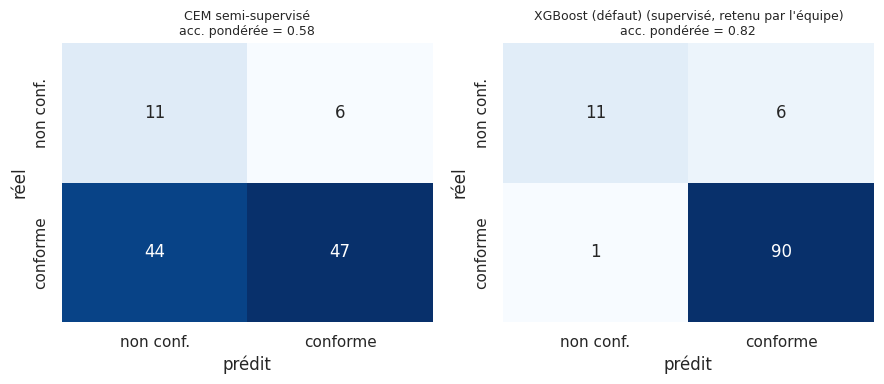

In [20]:
fig, axes = plt.subplots(1, len(NOMS_TEST), figsize=(4.5 * len(NOMS_TEST), 4))
for ax, nom in zip(np.atleast_1d(axes), NOMS_TEST):
    p = preds_test[preds_test["methode"] == nom]
    cm = ssl.confusion_matrix(p["y"], p["y_pred"], labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["non conf.", "conforme"], yticklabels=["non conf.", "conforme"])
    ax.set_title(f"{nom}\nacc. pondérée = {recap_test.loc[nom, 'Accuracy_ponderee']:.2f}", fontsize=9)
    ax.set_xlabel("prédit"); ax.set_ylabel("réel")
plt.tight_layout(); savefig("confusion_test"); plt.show()

In [21]:
# Le test est-il représentatif ? Répartition des soudures de test par publication, et erreurs par modèle
erreurs = (preds_test.assign(erreur=lambda d: (d["y"] != d["y_pred"]).astype(int))
           .pivot_table(index="groupe", columns="methode", values="erreur", aggfunc="sum")[NOMS_TEST])
compo = preds_test[preds_test["methode"] == NOM_RETENU].groupby("groupe")["y"].agg(
    n="size", non_conformes=lambda s: int((s == 0).sum()))
compo.join(erreurs.add_prefix("erreurs : ")).sort_values("n", ascending=False)

,n,non_conformes,erreurs : CEM semi-supervisé,"erreurs : XGBoost (défaut) (supervisé, retenu par l'équipe)"
groupe,,,,
Evans-AlTi-1994,84,6,46,6
PantK-1990,9,9,0,0
EvHtIp1979,7,0,0,0
Chandel&-1985,6,2,4,1
Blond&-1984,1,0,0,0
EvansLetterC+.5Moch1,1,0,0,0


In [22]:
# Pour information : score publié par le notebook 3 (imputation apprise sur le train seul, sans standardisation)
publie = pd.read_csv(P_REF / METHODE_REF / "test_recap_metriques.csv", sep=";", encoding="utf-8-sig", index_col=0)
publie

,CV (nouveaux découpages),Test,Baseline sur le test
F1,0.936666,0.968085,0.914573
Accuracy_ponderee,0.770368,0.823529,0.500000
Precision,0.924960,0.938144,0.842593
Recall,0.951665,1.000000,1.000000
ROC_AUC,0.912327,0.804137,0.500000


### 6.1 Analyse de l'évaluation finale

**La règle fixée à l'avance retient le CEM** (meilleure accuracy pondérée en validation croisée imbriquée : 0,850), mais son gain sur le XGBoost de l'équipe n'est **pas significatif** (+0,12, IC95 [−0,13 ; +0,30]). Le réglage final sur tout le train lui attribue **5 composantes**.

**Sur le test, le CEM s'effondre** : accuracy pondérée **0,582**, contre **0,818 pour le XGBoost de l'équipe**. Ce dernier score est cohérent avec celui publié par le notebook 3 (0,824) : notre pipeline reproduit bien le travail de l'équipe.

**Pourquoi un tel écart entre validation croisée et test ?** Le tableau par publication est éclairant : le test ne contient que **6 publications**, et **84 soudures sur 108 viennent d'une seule** (*Evans-AlTi-1994*, une étude des effets de Al et Ti). Le CEM s'y trompe 46 fois (des soudures conformes classées « non conformes »), le XGBoost 6 fois. Le CEM suppose que chaque classe est une gaussienne ; une série de soudures dont la composition sort de la zone où ces gaussiennes ont été estimées est mal classée, alors que les arbres de décision extrapolent plus prudemment. Le test mesure donc surtout **la capacité à généraliser à cette publication**.

**Lecture complémentaire (non décisionnelle)** : sur le test, aucune autre méthode semi-supervisée ne fait mieux que le XGBoost : self-training classique et équilibré 0,765, label spreading réglé 0,743.

**Limites de ce test** : 17 non conformes seulement, presque toutes dans 2 publications ; les IC bootstrap sur les publications sont **dégénérés** (borne haute à 1) car un tirage peut ne contenir aucune non conforme. Le test est donc peu informatif pour départager des méthodes ; la validation croisée (461 soudures, 5 plis) reste la base de la comparaison, et le test sert de **garde-fou**, qu'il a joué ici : il montre que l'avantage du CEM en validation croisée ne se généralise pas.

**Décision** : on conserve le **XGBoost supervisé de l'équipe** pour `Charpy conforme`. Aucune méthode semi-supervisée n'apporte de gain significatif, même après réglage des hyperparamètres, et la méthode retenue par notre règle est nettement moins bonne sur le test. Cette recommandation est enregistrée dans le JSON.

## 7. Sauvegarde (`05_reporting/semi_supervise/charpy/`)

Même logique que les notebooks supervisés :
- `modele_retenu_ssl.json` : méthode retenue et ses hyperparamètres, modèle de l'équipe, gains appariés, vérification des hypothèses, scores CV et test, paramètres du protocole ;
- `modele_final_ssl.joblib` : prétraitement + modèle retenu entraînés sur tout le train (+ $U$), réutilisables sans ré-entraîner ;
- CSV : prédictions hors-pli, scores par méthode et par fraction, prédictions du test ;
- `predictions_non_etiquetees.csv` : `Charpy conforme` prédit (et sa probabilité) pour **chaque soudure sans étiquette** de la base, par le modèle recommandé (XGBoost de l'équipe) et par le semi-supervisé retenu ; `ligne_df` renvoie à la ligne de `welddb_processed_vf.csv`, et `utilisee_en_apprentissage` vaut `False` pour les soudures des publications du test (écartées de $U$) ;
- réglage : prédictions de la validation croisée imbriquée, configurations choisies par pli, scores internes du réglage final.

In [23]:
def params_modele(est):
    '''Hyperparamètres utiles d'une méthode (on ne garde que les valeurs simples).'''
    p = est.get_params(deep=False)
    out = {k: v for k, v in p.items() if isinstance(v, (int, float, str, bool, type(None)))}
    if "estimator" in p:
        out["modele_de_base"] = NOM_REF
    if hasattr(est, "steps"):
        out = {f"{n}__{k}": v for n, s in est.steps for k, v in s.get_params(deep=False).items()
               if isinstance(v, (int, float, str, bool, type(None)))}
    return out

infos = {
    "cible": CIBLE,
    "definition_cible": "47 J à -40 °C (EN ISO 2560-A) ; interpolation de T(47 J) entre T(28 J) et T(100 J) — notebook 2, section 3.1",
    "type": "classification semi-supervisée",
    "score_de_selection": METRIQUE,
    "regle_de_choix": "meilleure accuracy pondérée en CV imbriquée (hyperparamètres réglés) à 100 % des étiquettes ; utile si la borne basse de l'IC95 du gain apparié > 0",
    "modele_retenu": NOM_RETENU,
    "famille": famille,
    "hyperparametres_retenu": params_modele(methodes_finales[NOM_RETENU][0]),
    "hyperparametres_regles_retenu": meilleurs_final.get(NOM_RETENU, {}),
    "reglage": "validation croisée imbriquée : 5 plis externes (évaluation) x 3 plis internes (réglage), groupés par publication",
    "grilles": {k: v for k, v in ssl.GRILLES_CLASSIFICATION.items()},
    "modele_equipe": {"nom": NOM_REF, "hyperparametres": ref["hyperparametres_retenu"],
                      "source": str(P_REF / METHODE_REF / "modele_retenu.json")},
    "gain_cv_vs_modele_equipe": {k: g_ret[k] for k in ["gain", "IC95_bas", "IC95_haut", "P(gain > 0)"]},
    "gain_significatif": UTILE,
    "score_cv_imbriquee": scores_n.to_dict(orient="index"),
    "ic95_cv_imbriquee": {m: list(v) for m, v in ic_n.items()},
    "gains_cv_imbriquee": gains_n.set_index("semi-supervisé")[["gain", "IC95_bas", "IC95_haut", "P(gain > 0)"]].to_dict(orient="index"),
    "score_cv_sans_reglage": s100.drop(columns=[f"{METRIQUE} IC95"]).to_dict(orient="index"),
    "hyperparametres_toutes_methodes": {n: params_modele(e) for n, (e, _) in methodes_finales.items()},
    "score_test": recap_test.drop(columns="rôle").to_dict(orient="index"),
    "recommandation": (f"{NOM_RETENU} (semi-supervisé)" if UTILE and
                       recap_test.loc[NOM_RETENU, METRIQUE] >= recap_test.loc[NOM_REF_LONG, METRIQUE]
                       else f"{NOM_REF} supervisé (notebook 3) : aucun gain semi-supervisé significatif en CV"
                            + ("" if recap_test.loc[NOM_RETENU, METRIQUE] >= recap_test.loc[NOM_REF_LONG, METRIQUE]
                               else ", et le semi-supervisé retenu est moins bon sur le test")),
    "n_etiquetees_train": int(len(y_tr)), "n_etiquetees_test": int(len(y_te)),
    "n_non_etiquetees": int(len(jeux["X_unl"])), "n_non_etiquetees_exclues_test": jeux["n_unl_exclues_test"],
    "variables_utilisees": jeux["X_lab"].columns.tolist() + ["CE_IIW", "courant"],
    "verification_hypotheses": hypotheses.to_dict(),
    "RANDOM_STATE": RANDOM_STATE, "N_FOLDS": N_FOLDS, "FRACTIONS": FRACTIONS,
    "N_TIRAGES": N_TIRAGES, "N_BOOT": N_BOOT,
    "split": str(P_REF / "split_train_test.csv"),
}
# Charpy conforme prédit sur les soudures sans étiquette (modèle recommandé + semi-supervisé retenu)
preds_unl = ssl.predire_non_etiquetees(df, df[CIBLE].notna(), jeux, COLONNES_A_RETIRER, prep_test,
                                       {n: modeles_test[n] for n in NOMS_TEST}, nom_cible=CIBLE)
dossier = ssl.enregistrer_ssl(P_SORTIE, infos, preds_cv, scores, preds_test,
                              modeles_test[NOM_RETENU], prep_test, preds_unl)
# Fichiers du réglage imbriqué
preds_n.to_csv(dossier / "cv_imbriquee_predictions.csv", index=False, **ssl.CSV)
choix_n.assign(parametres=choix_n["parametres"].astype(str)).to_csv(dossier / "cv_imbriquee_choix_par_pli.csv", index=False, **ssl.CSV)
reglage_final.assign(parametres=reglage_final["parametres"].astype(str)).to_csv(dossier / "reglage_final_scores_internes.csv", index=False, **ssl.CSV)
print("Enregistré dans", dossier)
print(sorted(p.name for p in dossier.iterdir()))

Enregistré dans ../1. Données/05_reporting/semi_supervise/Charpy_conforme
['cv_gains_apparies.csv', 'cv_imbriquee_choix_par_pli.csv', 'cv_imbriquee_gains_apparies.csv', 'cv_imbriquee_predictions.csv', 'cv_predictions.csv', 'cv_scores_par_methode_et_fraction.csv', 'modele_final_ssl.joblib', 'modele_retenu_ssl.json', 'reglage_final_scores_internes.csv', 'test_predictions.csv', 'test_recap_metriques.csv', 'verification_hypotheses.csv']


## 8. Conclusion

**Ce que montre ce notebook**
- Les hypothèses du semi-supervisé ne sont **que partiellement vérifiées** sur cette base : la lissité tient (y compris entre publications), mais près de la moitié des soudures non étiquetées décrivent des familles d'aciers sans aucun résultat Charpy, et elles rapprochent peu le test des données d'entraînement.
- **Aucune des trois familles du cours ne fait significativement mieux que le XGBoost retenu par l'équipe**, même après réglage des hyperparamètres par validation croisée imbriquée. Les deux méthodes les plus prometteuses (CEM : +0,12 ; self-training classique : +0,10) ont des intervalles qui contiennent 0 ; le réglage ramène le label spreading au niveau du XGBoost, sans le dépasser.
- **La méthode retenue par la règle (CEM) ne se généralise pas** au test, dominé par une publication dont la composition sort de la zone apprise par les gaussiennes. Le **XGBoost supervisé de l'équipe reste le meilleur modèle**.
- Le classement des méthodes dépend de la **définition de la cible** (−20 °C ou −40 °C) : sur une base aussi petite, les conclusions sur le semi-supervisé sont fragiles.

**Pourquoi c'est un résultat valable** : la littérature montre que les données non étiquetées n'aident que si leurs hypothèses sont satisfaites, et peuvent même dégrader les performances sinon (Singh et al., 2008 ; Oliver et al., 2018 ; van Engelen & Hoos, 2020). Ici, le principal obstacle n'est pas le manque d'étiquettes mais la **généralisation à des publications jamais vues**, que des soudures non étiquetées issues d'autres études ne peuvent pas résoudre.

**Pistes d'amélioration**
1. Construire le graphe du label spreading dans un meilleur espace (variables métallurgiques clés, ou proximités d'une forêt aléatoire), plutôt qu'en distance euclidienne sur toutes les variables.
2. Ajuster le seuil de décision (0,5 par défaut) pour favoriser la détection des non conformes, l'erreur la plus coûteuse.
3. Vérifier la robustesse des conclusions avec une autre température d'exigence (−20 °C, −60 °C).

